---
title: "3.7.d Escenarios: dengue en un clima más cálido"
short_title: "d. Escenarios"
subtitle: "Temperatura media proyectada (CMIP6) frente a la respuesta térmica de la transmisión"
description: "Escenarios de aptitud térmica para la transmisión del dengue en Leticia con el ensamble CMIP6 del Banco Mundial."
keywords: [dengue, CMIP6, temperatura, escenarios, Aedes aegypti, Leticia]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/37_dengue/d_escenarios.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

La relación entre temperatura y transmisión no es lineal: sube hasta un óptimo y cae cuando hace demasiado calor para
el mosquito [@mordecai2017]. Por eso el calentamiento puede aumentar la aptitud para la transmisión en lugares
frescos y reducirla en lugares que ya están cerca del óptimo. Esta página ubica a Leticia en esa curva con las
proyecciones del ensamble CMIP6 del Banco Mundial.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from leticia import fuentes, salud, viz
from leticia.config import parametros

pdg = parametros()["dengue"]
semanal = fuentes.dengue_opendengue()
mensual = salud.casos_mensuales(semanal)

## 1. Temperatura media mensual proyectada

In [3]:
tabla = fuentes.cckp_tabla(["tas"])
tas = tabla[tabla.variable == "tas"]
era = fuentes.clima_diario()
clim = era["temperature_2m_mean"].loc["1995":"2014"].groupby(lambda f: f.month).mean()   # mismo periodo base que el CCKP
filas, meses_clase = [], {}
for (esc, per), g in tas.groupby(["escenario", "periodo"]):
    d = g.set_index("percentil")["valor"]
    futuro = clim + d["median"]
    clase = salud.aptitud_termica(futuro, pdg["temperatura_limite_inferior"], tuple(pdg["rango_transmision_maxima"]), pdg["temperatura_limite_superior"])
    filas.append({"escenario": viz.NOMBRE_ESC[esc], "periodo": per, "cambio (°C, mediana)": d["median"], "rango p10–p90": f"{d['p10']:+.1f} a {d['p90']:+.1f}",
                  "temperatura media anual (°C)": futuro.mean(), "meses en transmisión máxima": int((clase == "máxima transmisión").sum()),
                  "meses sobre el óptimo": int((clase == "sobre el óptimo").sum())})
    meses_clase[(esc, per)] = futuro
base_clase = salud.aptitud_termica(clim, pdg["temperatura_limite_inferior"], tuple(pdg["rango_transmision_maxima"]), pdg["temperatura_limite_superior"])
filas.insert(0, {"escenario": "ERA5 1995–2014", "periodo": "base", "cambio (°C, mediana)": 0.0, "rango p10–p90": "",
                 "temperatura media anual (°C)": clim.mean(), "meses en transmisión máxima": int((base_clase == "máxima transmisión").sum()),
                 "meses sobre el óptimo": int((base_clase == "sobre el óptimo").sum())})
display(pd.DataFrame(filas).set_index(["escenario", "periodo"]).round(2))

cambio (°C, mediana) rango p10–p90  temperatura media anual (°C)  meses en transmisión máxima  \
escenario      periodo                                                                                                    
ERA5 1995–2014 base                       0.00                                       26.06                            8   
SSP1-2.6       2040-2059                  0.99   +0.6 a +1.9                         27.05                           12   
               2080-2099                  1.06   +0.4 a +2.2                         27.12                           12   
SSP2-4.5       2040-2059                  1.24   +0.8 a +2.3                         27.30                           12   
               2080-2099                  2.14   +1.1 a +3.6                         28.20                           12   
SSP5-8.5       2040-2059                  1.75   +0.9 a +3.1                         27.82                           12   
               2080-2099                  4.57   +2.3 a +8.3                         30.63                            0   

                          meses sobre el óptimo  
escenario      periodo                           
ERA5 1995–2014 base                           0  
SSP1-2.6       2040-2059                      0  
               2080-2099                      0  
SSP2-4.5       2040-2059                      0  
               2080-2099                      0  
SSP5-8.5       2040-2059                      0  
               2080-2099                     12

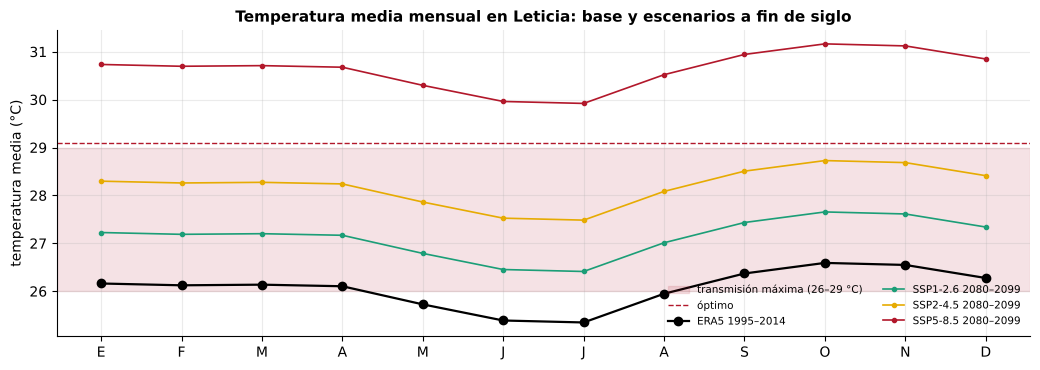

In [4]:
fig, ax = plt.subplots(figsize=(10.5, 3.8))
ax.axhspan(*pdg["rango_transmision_maxima"], color=viz.ROJO, alpha=0.12, label="transmisión máxima (26–29 °C)")
ax.axhline(pdg["temperatura_optima"], color=viz.ROJO, lw=1, ls="--", label="óptimo")
ax.plot(clim.index, clim, "k-o", lw=1.6, label="ERA5 1995–2014")
for esc in ("ssp126", "ssp245", "ssp585"):
    ax.plot(clim.index, meses_clase[(esc, "2080-2099")], "-o", color=viz.ESCENARIOS[esc], lw=1.2, ms=3, label=f"{viz.NOMBRE_ESC[esc]} 2080–2099")
ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("EFMAMJJASOND"))
ax.set_ylabel("temperatura media (°C)")
ax.set_title("Temperatura media mensual en Leticia: base y escenarios a fin de siglo")
ax.legend(fontsize=7.5, ncol=2)
fig.tight_layout()

In [5]:
viz.pie(viz.nota_fuente("proyecciones_cckp", "clima_diario") + " Método delta: cambio anual de la mediana del ensamble sumado a la climatología mensual.")

Fuente: Banco Mundial – Climate Change Knowledge Portal (CCKP) — CMIP6 0,25° (reducción de escala estadística), SSP1-2.6, SSP2-4.5, SSP5-8.5; ECMWF ERA5 (vía Open-Meteo) — Reanálisis ERA5, celda 0,25°. Método delta: cambio anual de la mediana del ensamble sumado a la climatología mensual.

**Lectura.** Con emisiones bajas o intermedias, la temperatura media de Leticia se mueve **dentro** del rango de
transmisión máxima y se acerca al óptimo: más meses al año con condiciones térmicas muy favorables para el dengue.
Con emisiones altas, hacia fin de siglo la temperatura media pasa **por encima del óptimo** todos los meses;
según la curva de Mordecai et al., la transmisión dejaría de aumentar y empezaría a disminuir en los meses más
cálidos, aunque seguiría lejos del límite superior de 34,6 °C. Es una lectura de **aptitud térmica**, no de casos:
la urbanización, el almacenamiento de agua, la inmunidad y el control vectorial pesan tanto como el clima. El
método delta aplica el cambio anual a todos los meses y no capta cambios en la estacionalidad.